# EDA i podział danych: SMS Spam Collection (Milestone 1)

Notebook:
1. wczytuje dane i opisuje etykiety, braki i duplikaty,
2. wykrywa bliskie duplikaty i tworzy zamrożony podział 70/15/15 (seed 42) bez przecieku między częściami,
3. na zbiorze treningowym szuka sygnałów, które uzasadniają warianty przetwarzania P1-P3.

Fakty o zbiorze (liczebności, duplikaty, podział) liczymy na wszystkich rekordach. Wszystko, co uzasadnia wariant przetwarzania, liczymy **tylko na treningu**, a słownictwo spoza słownika sprawdzamy na parze train → val. Test nie wpływa na wybór wariantów.

Zapisuje: `data/splits/split_seed42.csv` (+ `.meta.json`) oraz wykresy do `reports/milestone1/`. Podział jest zamrożony: ponowne uruchomienie sprawdza, że wychodzi identyczny, i niczego nie nadpisuje.

Uruchomienie: `uv sync`, potem notebook w PyCharm / `uv run jupyter lab`, albo w całości:
`uv run jupyter nbconvert --to notebook --execute --inplace notebooks/01_eda.ipynb`

## 0. Konfiguracja

In [1]:
import hashlib
import json
import platform
import re
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import sparse
from scipy.sparse.csgraph import connected_components
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import StratifiedGroupKFold

from smsspam import patterns as P
from smsspam.data import ROOT, SPLIT_DIR, load_config, load_raw

cfg = load_config()
OUT = ROOT / "reports" / "milestone1"
OUT.mkdir(parents=True, exist_ok=True)
LABELS = ("ham", "spam")
# Validated categorical slots 1-2 (light mode); the slides use the same hues.
COLORS = {"ham": "#2a78d6", "spam": "#eb6834"}
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
# scikit-learn default; B1 uses the same tokenisation.
TOKEN_PATTERN = r"(?u)\b\w\w+\b"

pd.set_option("display.max_colwidth", 140)


def share(mask) -> float:
    return round(float(np.mean(mask)), 4)


def style(ax, grid_axis="x"):
    ax.set_facecolor(SURFACE)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=INK_2, labelsize=13, length=0)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)

## 1. Wczytanie danych

`load_raw()` pobiera archiwum z UCI (tylko raz), sprawdza SHA-256 pliku i zwraca surowy tekst bez żadnego czyszczenia. `id` to numer linii w oryginalnym pliku.

In [2]:
df = load_raw()
print({k: cfg["source"][k] for k in ("name", "uci_id", "license", "downloaded", "file_sha256")})
print(df.shape)
df.head()

{'name': 'SMS Spam Collection v.1', 'uci_id': 228, 'license': 'CC BY 4.0', 'downloaded': '2026-10-29', 'file_sha256': '7d039a24a6083ed9ef0f806ebad56bbb976e3aeb8de05669173bfdc4996c239d'}
(5574, 3)


,id,label,text
0,0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,1,ham,Ok lar... Joking wif u oni...
2,2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply ...
3,3,ham,U dun say so early hor... U c already then say...
4,4,ham,"Nah I don't think he goes to usf, he lives around here though"


## 2. Etykiety i braki

In [3]:
counts = df.label.value_counts().to_frame("liczba")
counts["udział"] = (counts.liczba / len(df)).round(3)
display(counts)

text = df.text
pd.Series({
    "puste lub same spacje": (text.str.strip() == "").sum(),
    "spacja na początku/końcu": (text != text.str.strip()).sum(),
    "min. długość [znaki]": text.str.len().min(),
    "maks. długość [znaki]": text.str.len().max(),
    "z emoji": text.str.contains(P.EMOJI).sum(),
    "ze znakiem C1 z cp1252 (np. \\x92)": text.str.contains(P.C1_CONTROL).sum(),
    "z encją HTML (&lt; &gt; &amp;)": text.str.contains(P.HTML_ENTITY).sum(),
}).to_frame("wiadomości")

,liczba,udział
label,,
ham,4827,0.866
spam,747,0.134


,wiadomości
puste lub same spacje,0
spacja na początku/końcu,187
min. długość [znaki],2
maks. długość [znaki],910
z emoji,0
ze znakiem C1 z cp1252 (np. \x92),35
z encją HTML (&lt; &gt; &amp;),309


- 13,4% spamu, zgodnie z readme zbioru. Klasy są niezbalansowane, dlatego metryką główną jest F1 dla spamu, a nie accuracy.
- Brak pustych wiadomości. Spacji na brzegach nie przycinamy: B1 ma dostać surowy tekst.
- Brak emoji (korpus z 2011 r.), więc obsługa emoji nie ma sensu jako wariant.
- Kilkadziesiąt wiadomości ma nieprzekodowane znaki cp1252 (`\x92` zamiast `’`) albo encje HTML. Wracamy do tego w sekcji 9.

## 3. Przykładowe wiadomości

In [4]:
df.groupby("label").sample(5, random_state=42)[["id", "label", "text"]]

,id,label,text
688,688,ham,"Dear,Me at cherthala.in case u r coming cochin pls call bfore u start.i shall also reach accordingly.or tell me which day u r coming.tmo..."
2520,2520,ham,Ok. I only ask abt e movie. U wan ktv oso?
1079,1079,ham,Convey my regards to him
1724,1724,ham,"Hi Jon, Pete here, Ive bin 2 Spain recently & hav sum dinero left, Bill said u or ur rents mayb interested in it, I hav 12,000pes, so a..."
1974,1974,ham,I had askd u a question some hours before. Its answer
3290,3290,spam,Camera - You are awarded a SiPix Digital Camera! call 09061221066 fromm landline. Delivery within 28 days
3014,3014,spam,FREE UNLIMITED HARDCORE PORN direct 2 your mobile Txt PORN to 69200 & get FREE access for 24 hrs then chrgd@50p per day txt Stop 2exit. ...
752,752,spam,You have an important customer service announcement from PREMIER.
3010,3010,spam,Update_Now - 12Mths Half Price Orange line rental: 400mins...Call MobileUpd8 on 08000839402 or call2optout=J5Q
1780,1780,spam,"Loan for any purpose £500 - £75,000. Homeowners + Tenants welcome. Have you been previously refused? We can still help. Call Free 0800 1..."


## 4. Dokładne duplikaty

In [5]:
redundant = df.duplicated("text")
display(pd.DataFrame({
    "nadmiarowe kopie": df[redundant].label.value_counts(),
    "% klasy": (100 * df[redundant].label.value_counts() / df.label.value_counts()).round(1),
}))
print("unikalne teksty:", df.text.nunique())
print("teksty z konfliktem etykiet:", (df.groupby("text").label.nunique() > 1).sum())
df.text.value_counts().head(5).to_frame("powtórzenia")

,nadmiarowe kopie,% klasy
label,,
ham,309,6.4
spam,94,12.6


unikalne teksty: 5171
teksty z konfliktem etykiet: 0


,powtórzenia
text,
"Sorry, I'll call later",30
I cant pick the phone right now. Pls send a message,12
Ok...,10
Please call our customer service representative on FREEPHONE 0808 145 4742 between 9am-11pm as you have WON a guaranteed £1000 cash or £5000 prize!,4
"Wen ur lovable bcums angry wid u, dnt take it seriously.. Coz being angry is d most childish n true way of showing deep affection, care n luv!.. kettoda manda... Have nice day da.",4


- 403 nadmiarowe kopie (7,2%) i żadnego tekstu z dwiema różnymi etykietami.
- Spam powtarza się dwa razy częściej niż ham (12,6% vs 6,4%): te same kampanie wysyłano wielokrotnie.
- Dokładny duplikat w treningu i teście oznacza wprost „widziany” przykład testowy, więc grupujemy je przy podziale.

## 5. Bliskie duplikaty

Wiadomości różniące się numerem, kwotą lub jednym słowem też są „tym samym” przykładem. Porównujemy je cosinusem TF-IDF n-gramów znakowych 3-5, łączymy pary powyżej progu i bierzemy składowe spójne grafu jako grupy.

Wektoryzator widzi wszystkie teksty, ale nie etykiety. To kontrola podziału, a nie cecha modelu.

In [6]:
nd = cfg["near_dup"]
X = TfidfVectorizer(
    analyzer=nd["analyzer"], ngram_range=(nd["ngram_min"], nd["ngram_max"]), sublinear_tf=True
).fit_transform(df.text)
sim = sparse.triu(X @ X.T, k=1).tocoo()
y, texts = df.label.to_numpy(), df.text.to_numpy()


def groups_at(threshold: float) -> np.ndarray:
    keep = sim.data >= threshold
    adj = sparse.coo_matrix((np.ones(keep.sum()), (sim.row[keep], sim.col[keep])), shape=(len(df), len(df)))
    return connected_components(adj, directed=False)[1]


rows = []
for th in (0.95, 0.9, 0.8, 0.7, 0.6, 0.5):
    keep = sim.data >= th
    sizes = np.bincount(g := groups_at(th))
    rows.append({
        "próg": th,
        "pary": keep.sum(),
        "pary nieidentyczne": (texts[sim.row[keep]] != texts[sim.col[keep]]).sum(),
        "pary ham-spam": (y[sim.row[keep]] != y[sim.col[keep]]).sum(),
        "grupy": len(sizes),
        "największa grupa": sizes.max(),
        "rekordy w grupach > 1": (sizes[g] > 1).sum(),
    })
pd.DataFrame(rows).set_index("próg")

,pary,pary nieidentyczne,pary ham-spam,grupy,największa grupa,rekordy w grupach > 1
próg,,,,,,
0.95,1068,84,0,5114,30,777
0.90,1154,170,0,5065,30,852
0.80,1408,424,0,4990,36,954
0.70,1739,755,0,4897,40,1061
0.60,2206,1222,0,4763,45,1218
0.50,2971,1987,0,4475,49,1553


Przy żadnym progu nie ma pary ham-spam, a największa grupa rośnie powoli (brak „łańcuchów”). Jak wyglądają pary w pasmach wokół progu:

In [7]:
rng = np.random.default_rng(0)
for lo, hi in ((0.7, 0.8), (0.6, 0.7)):
    for lab in LABELS:
        idx = np.flatnonzero((sim.data >= lo) & (sim.data < hi) & (y[sim.row] == lab))
        print(f"--- [{lo}, {hi}) {lab}: {len(idx)} par")
        for i in rng.choice(idx, 3, replace=False):
            print(f"  {sim.data[i]:.2f}  A: {texts[sim.row[i]][:100]}")
            print(f"        B: {texts[sim.col[i]][:100]}")

--- [0.7, 0.8) ham: 192 par
  0.77  A: Sorry, I'll call later
        B: Sorry, I'll call later In meeting.
  0.74  A: Sorry, I'll call later
        B: Sorry, I'll call later  &lt;#&gt; mins
  0.74  A: Sorry, I'll call later
        B: Sorry, I'll call later  &lt;#&gt; mins
--- [0.7, 0.8) spam: 139 par
  0.72  A: Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera f
        B: December only! Had your mobile 11mths+? You are entitled to update to the latest colour camera mobil
  0.71  A: We tried to contact you re your reply to our offer of a Video Handset? 750 anytime networks mins? UN
        B: We tried to call you re your reply to our sms for a video mobile 750 mins UNLIMITED TEXT + free camc
  0.73  A: PRIVATE! Your 2004 Account Statement for 07742676969 shows 786 unredeemed Bonus Points. To claim cal
        B: PRIVATE! Your 2004 Account Statement for 078498****7 shows 786 unredeemed Bonus Points. To claim cal


--- [0.6, 0.7) ham: 267 par
  0.63  A: Sorry, I'll call later
        B: Sorry, I'll call you  later. I am in meeting sir.
  0.61  A: Sorry i'm not free...
        B: Can... I'm free...
  0.62  A: Good morning princess! Happy New Year!
        B: Good morning princess! Have a great day!
--- [0.6, 0.7) spam: 200 par
  0.68  A: Urgent Please call 09066612661 from landline. £5000 cash or a luxury 4* Canary Islands Holiday await
        B: Urgent! Please call 09061213237 from landline. £5000 cash or a luxury 4* Canary Islands Holiday awai
  0.69  A: PRIVATE! Your 2003 Account Statement for shows 800 un-redeemed S. I. M. points. Call 08719899230 Ide
        B: PRIVATE! Your 2003 Account Statement for shows 800 un-redeemed S.I.M. points. Call 08718738001 Ident
  0.67  A: Dear 0776xxxxxxx U've been invited to XCHAT. This is our final attempt to contact u! Txt CHAT to 866
        B: Hi there, 2nights ur lucky night! Uve been invited 2 XCHAT, the Uks wildest chat! Txt CHAT to 86688 


- W paśmie 0,7-0,8 spam to wciąż ten sam szablon z innym numerem lub kwotą. To bliskie duplikaty.
- Poniżej 0,7 zaczynają się łączyć hamy, które dzielą tylko wspólną frazę („Sorry i'm not free...” / „Can... I'm free...”, „Good morning princess! Happy New Year!” / „…Have a great day!”).

**Decyzja:** próg 0,7. Zostawiamy wszystkie rekordy (naturalny rozkład klas w teście), a każda grupa trafia w całości do jednej części podziału.

In [8]:
df["dup_group"] = groups_at(nd["threshold"])
df.dup_group.nunique()

4897

## 6. Podział 70/15/15

Brak oficjalnego podziału, więc `StratifiedGroupKFold` z 20 foldami (po ~5%): 3 foldy to test, 3 walidacja, 14 trening. Stratyfikacja po etykiecie, grupy z sekcji 5, seed 42.

In [9]:
sc = cfg["split"]
n_test, n_val = round(sc["test"] * sc["n_folds"]), round(sc["val"] * sc["n_folds"])
sgkf = StratifiedGroupKFold(n_splits=sc["n_folds"], shuffle=True, random_state=sc["seed"])
fold = np.empty(len(df), dtype=int)
for k, (_, idx) in enumerate(sgkf.split(np.zeros(len(df)), df.label, df.dup_group)):
    fold[idx] = k
df["split"] = np.where(fold < n_test, "test", np.where(fold < n_test + n_val, "val", "train"))

table = df.groupby(["split", "label"]).size().unstack().reindex(["train", "val", "test"])
table["razem"] = table.sum(axis=1)
table["% spam"] = (100 * table.spam / table.razem).round(1)
table

label,ham,spam,razem,% spam
split,,,,
train,3378,522,3900,13.4
val,725,112,837,13.4
test,724,113,837,13.5


**Kontrola przecieku.** Żadna grupa ani identyczny tekst nie może być w dwóch częściach. Dla każdego rekordu z walidacji i testu liczymy też najwyższe podobieństwo do dowolnego rekordu treningowego.

In [10]:
assert (df.groupby("dup_group").split.nunique() == 1).all()
assert (df.groupby("text").split.nunique() == 1).all()

train_idx = np.flatnonzero(df.split == "train")
max_sim = (X @ X[train_idx].T).max(axis=1).toarray().ravel()
max_sim[train_idx] = np.nan
df["max_sim_to_train"] = max_sim
held_out = df[df.split != "train"]
assert (held_out.max_sim_to_train < nd["threshold"]).all()

pd.DataFrame({
    f"cos >= {th}": held_out[held_out.max_sim_to_train >= th].groupby(["split", "label"]).size()
    for th in (0.5, 0.6)
}).fillna(0).astype(int)

cos >= 0.5  cos >= 0.6
split label                        
test  ham            79          25
      spam           41          24
val   ham            73          17
      spam           25          16

In [11]:
test = df[df.split == "test"]
group_size = df.dup_group.map(df.dup_group.value_counts())
print("unikalne teksty w teście:", test.text.nunique(), "z", len(test))
print("rekordy testu w grupach > 1:", test[group_size[test.index] > 1].label.value_counts().to_dict())
print("największe grupy:")
df.groupby("dup_group").agg(n=("id", "size"), label=("label", "first"), split=("split", "first"), text=("text", "first")).nlargest(5, "n")

unikalne teksty w teście: 781 z 837
rekordy testu w grupach > 1: {'ham': 92, 'spam': 65}
największe grupy:


,n,label,split,text
dup_group,,,,
57,40,ham,val,"Sorry, I'll call later in meeting."
291,12,ham,test,I cant pick the phone right now. Pls send a message
1196,12,ham,test,Ok...
269,11,ham,test,Thanx...
252,10,spam,train,We tried to contact you re your reply to our offer of a Video Handset? 750 anytime networks mins? UNLIMITED TEXT? Camcorder? Reply or ca...


- Proporcja spamu w każdej części wynosi 13,4-13,5%.
- Żaden rekord z walidacji ani testu nie ma podobieństwa ≥ 0,7 do treningu.
- Zostaje pasmo 0,5-0,7 (w teście 41 spamów): te same kampanie w innej wersji. To realistyczne, ale może zawyżać wynik, dlatego pokażemy też wynik na podzbiorze testu z podobieństwem < 0,5.
- 65 ze 113 spamów testu należy do grup duplikatów wewnątrz testu, więc te kampanie liczą się podwójnie. Dlatego raportujemy też wynik na teście po deduplikacji.
- Grupa „Sorry, I'll call later” (40 rekordów) trafiła w całości do walidacji.

Zapis zamrożonego podziału. Jeśli plik już istnieje, sprawdzamy tylko, że wyszedł identyczny:

In [12]:
df["text_sha1"] = df.text.map(lambda t: hashlib.sha1(t.encode()).hexdigest())
split = df[["id", "label", "split", "dup_group", "text_sha1"]]
split_path = SPLIT_DIR / f"split_seed{sc['seed']}.csv"
if split_path.exists():
    pd.testing.assert_frame_equal(split, pd.read_csv(split_path), check_dtype=False)
    print("podział zgodny z zamrożonym:", split_path.relative_to(ROOT))
else:
    SPLIT_DIR.mkdir(parents=True, exist_ok=True)
    split.to_csv(split_path, index=False)
    print("zapisano:", split_path.relative_to(ROOT))

sizes = df.dup_group.value_counts()
meta = {
    "source": cfg["source"],
    "split_config": sc,
    "near_dup_config": nd,
    "n_records": len(df),
    "counts": df.groupby(["split", "label"]).size().unstack().to_dict(orient="index"),
    "spam_share": df.groupby("split").label.apply(lambda s: round((s == "spam").mean(), 4)).to_dict(),
    "n_groups": int(df.dup_group.nunique()),
    "records_in_multi_groups": int((df.dup_group.map(sizes) > 1).sum()),
    "largest_group": int(sizes.max()),
    "held_out_max_sim_to_train": {
        "median": round(float(held_out.max_sim_to_train.median()), 4),
        "counts": {
            f">={th}": {s: int(((df.max_sim_to_train >= th) & (df.split == s)).sum()) for s in ("val", "test")}
            for th in (0.5, 0.6, 0.7)
        },
    },
    "environment": {
        "python": platform.python_version(),
        **{pkg: version(pkg) for pkg in ("numpy", "pandas", "scipy", "scikit-learn")},
    },
}
meta_path = SPLIT_DIR / f"split_seed{sc['seed']}.meta.json"
meta_path.write_text(json.dumps(meta, indent=2, ensure_ascii=False) + "\n")
print("zapisano:", meta_path.relative_to(ROOT))

podział zgodny z zamrożonym: data/splits/split_seed42.csv
zapisano: data/splits/split_seed42.meta.json


## 7. Długość wiadomości (train)

Od tego miejsca pracujemy tylko na treningu (oraz na walidacji w sekcji 10).

In [13]:
train, val = df[df.split == "train"], df[df.split == "val"]
chars, words = train.text.str.len(), train.text.str.split().str.len()
rows = {}
for lab in LABELS:
    m = train.label == lab
    rows[lab] = {
        "mediana znaków": chars[m].median(),
        "Q1": chars[m].quantile(0.25),
        "Q3": chars[m].quantile(0.75),
        "mediana słów": words[m].median(),
        "% 120-160 znaków": 100 * share(chars[m].between(120, 160)),
        "% > 160 znaków": 100 * share(chars[m] > 160),
    }
pd.DataFrame(rows).T

,mediana znaków,Q1,Q3,mediana słów,% 120-160 znaków,% > 160 znaków
ham,53.0,34.0,94.75,11.0,13.00,4.59
spam,149.0,134.0,157.00,25.0,74.71,8.81


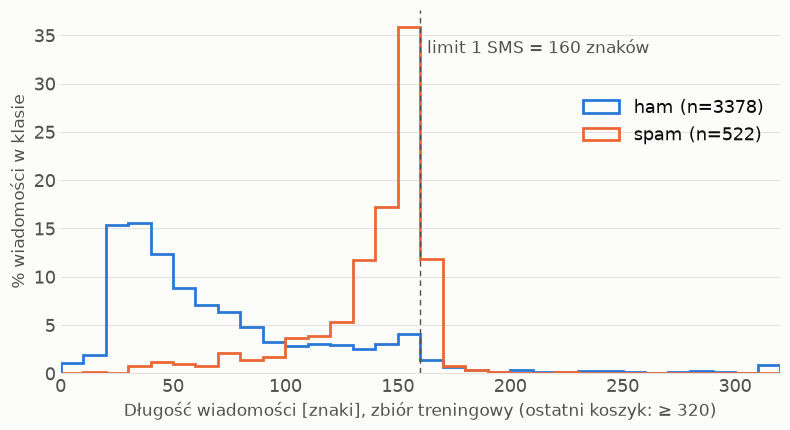

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.4), facecolor=SURFACE)
style(ax, grid_axis="y")
bins = np.arange(0, 330, 10)
clipped = chars.clip(upper=bins[-1] - 1)
for lab in LABELS:
    c = clipped[train.label == lab]
    ax.hist(c, bins=bins, weights=np.full(len(c), 100 / len(c)), histtype="step", linewidth=2,
            color=COLORS[lab], label=f"{lab} (n={len(c)})")
ax.axvline(160, color=INK_2, linewidth=1, linestyle=(0, (4, 3)))
ax.text(163, ax.get_ylim()[1] * 0.92, "limit 1 SMS = 160 znaków", color=INK_2, fontsize=12, va="top")
ax.set_xlabel("Długość wiadomości [znaki], zbiór treningowy (ostatni koszyk: ≥ 320)", color=INK_2, fontsize=12.5)
ax.set_ylabel("% wiadomości w klasie", color=INK_2, fontsize=12.5)
ax.set_xlim(0, bins[-1])
ax.legend(frameon=False, fontsize=13, labelcolor=INK, loc="upper right", bbox_to_anchor=(1, 0.8))
fig.tight_layout()
fig.savefig(OUT / "fig_length.png", dpi=200)

Spam celuje w limit jednego SMS-a: mediana 149 znaków i 74,7% spamu w przedziale 120-160. Ham jest krótki (mediana 53). Długość to silny sygnał, ale TF-IDF w B1 widzi ją tylko pośrednio.

## 8. Znaczniki w tekście (train)

Wzorce z `smsspam/patterns.py`. Te same wyrażenia posłużą w M2 do maskowania w wariantach P.

In [15]:
MARKERS = {
    "Numer telefonu (>= 8 cyfr)": P.PHONE,
    "Kod krótki (5-6 cyfr)": P.SHORTCODE,
    "Kwota (£, $, 150p)": P.MONEY,
    "URL / domena": P.URL,
    "Encja HTML (&lt; &gt; &amp;)": P.HTML_ENTITY,
    "Emotikona :) ;-)": P.EMOTICON,
    "Wielokropek / !!! / ???": P.REPEATED_PUNCT,
    "Powtórzona litera (sooo)": P.REPEATED_LETTER,
    "Znak C1 z cp1252 (\\x92)": P.C1_CONTROL,
}


def uppercase_heavy(t: str) -> bool:
    letters = [c for c in t if c.isalpha()]
    return len(letters) >= 10 and sum(c.isupper() for c in letters) / len(letters) >= 0.5


hits = {name: train.text.map(lambda t, pat=pat: pat.search(t) is not None) for name, pat in MARKERS.items()}
hits["Przewaga wielkich liter (>= 50%)"] = train.text.map(uppercase_heavy)
prev = pd.DataFrame({lab: {name: share(h[train.label == lab]) for name, h in hits.items()} for lab in LABELS})
prev.mul(100).round(1)

,ham,spam
Numer telefonu (>= 8 cyfr),0.1,61.5
Kod krótki (5-6 cyfr),0.0,34.1
"Kwota (£, $, 150p)",0.3,51.7
URL / domena,0.3,18.2
Encja HTML (&lt; &gt; &amp;),6.7,0.0
Emotikona :) ;-),3.3,0.0
Wielokropek / !!! / ???,15.7,1.7
Powtórzona litera (sooo),2.3,2.9
Znak C1 z cp1252 (\x92),0.8,0.4
Przewaga wielkich liter (>= 50%),2.3,3.1


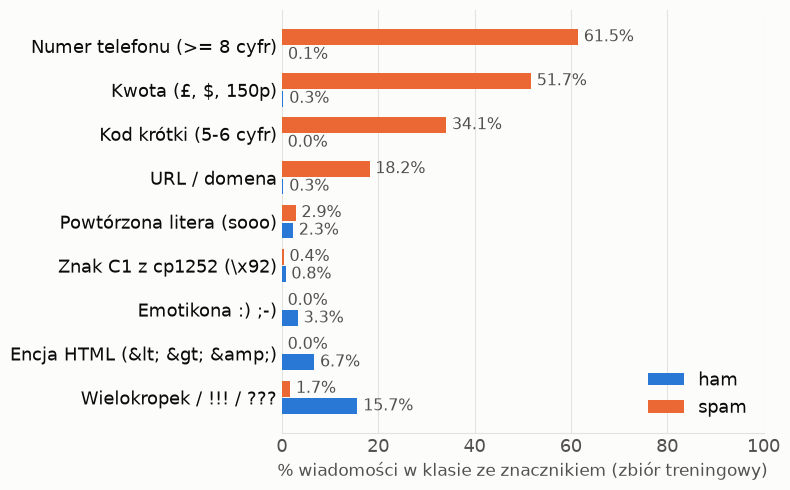

In [16]:
plot = prev.drop(index="Przewaga wielkich liter (>= 50%)").assign(diff=lambda d: d.spam - d.ham).sort_values("diff")
pos, h = np.arange(len(plot)), 0.36
fig, ax = plt.subplots(figsize=(8, 5), facecolor=SURFACE)
style(ax)
for offset, lab in ((h / 2 + 0.02, "spam"), (-h / 2 - 0.02, "ham")):
    vals = plot[lab].to_numpy() * 100
    ax.barh(pos + offset, vals, height=h, color=COLORS[lab], label=lab)
    for yi, v in zip(pos + offset, vals):
        ax.text(v + 1.2, yi, f"{v:.1f}%", va="center", fontsize=11.5, color=INK_2)
ax.set_yticks(pos, plot.index, color=INK)
ax.set_xlim(0, 100)
ax.set_xlabel("% wiadomości w klasie ze znacznikiem (zbiór treningowy)", color=INK_2, fontsize=12.5)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], frameon=False, fontsize=13, loc="lower right", labelcolor=INK)
fig.tight_layout()
fig.savefig(OUT / "fig_markers.png", dpi=200)

Co wzorce faktycznie łapią w spamie:

In [17]:
sample = train[train.label == "spam"].head(8)
found = {
    name: sample.text.map(lambda t, pat=pat: ", ".join(m.group(0) for m in pat.finditer(t)))
    for name, pat in {"PHONE": P.PHONE, "SHORTCODE": P.SHORTCODE, "MONEY": P.MONEY, "URL": P.URL}.items()
}
pd.DataFrame({"text": sample.text.str.slice(0, 70), **found}).set_index(sample.id)

,text,PHONE,SHORTCODE,MONEY,URL
id,,,,,
2,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Te,08452810075,87121,,
8,WINNER!! As a valued network customer you have been selected to receiv,09061701461,,£900,
9,Had your mobile 11 months or more? U R entitled to Update to the lates,08002986030,,,
15,"XXXMobileMovieClub: To use your credit, click the WAP link in the next",,,,"http://wap., xxxmobilemovieclub.com?n=QJKGIGHJJGCBL"
42,07732584351 - Rodger Burns - MSG = We tried to call you re your reply,"07732584351, 08000930705",,,
65,"As a valued customer, I am pleased to advise you that following recent",09066364589,,£1500,
93,Please call our customer service representative on 0800 169 6031 betwe,0800 169 6031,,"£1000, £5000",
95,Your free ringtone is waiting to be collected. Simply text the passwor,,85069,,


- Numer telefonu (61,5% vs 0,1%), kwota (51,7% vs 0,3%) i kod krótki (34,1% vs 0%) to niemal wyłącznie spam.
- Wielokropki i emotikony to cechy hamu, ale domyślny tokenizer B1 (`\b\w\w+\b`) pomija interpunkcję.
- Powtórzone litery („sooo”) i przewaga wielkich liter są rzadkie i podobnie częste w obu klasach.

## 9. Artefakt korpusu: `&lt;#&gt;`

In [18]:
placeholder = train.text.str.contains("&lt;#&gt;", regex=False)
display(train[placeholder].label.value_counts())
train[placeholder][["id", "label", "text"]].head(5)

label
ham    155
Name: count, dtype: int64

,id,label,text
44,44,ham,Great! I hope you like your man well endowed. I am &lt;#&gt; inches...
51,51,ham,"A gram usually runs like &lt;#&gt; , a half eighth is smarter though and gets you almost a whole second gram for &lt;#&gt;"
78,78,ham,Does not operate after &lt;#&gt; or what
178,178,ham,"Turns out my friends are staying for the whole show and won't be back til ~ &lt;#&gt; , so feel free to go ahead and smoke that $ &lt;#&..."
200,200,ham,"Found it, ENC &lt;#&gt; , where you at?"


`&lt;#&gt;` to zakodowane `<#>`, czyli placeholder, którym korpus NUS (źródło większości hamów) zastąpił liczby przy anonimizacji. Występuje wyłącznie w hamie. Tokenizer B1 zrobi z niego tokeny `lt` i `gt`, a w sekcji 11 widać, że to dwa najsilniejsze tokeny hamu. Model może więc nauczyć się artefaktu zbierania danych zamiast języka.

## 10. Słownictwo spoza treningu (słownik B1 z train, sprawdzany na val)

In [19]:
vocab = set(CountVectorizer(token_pattern=TOKEN_PATTERN).fit(train.text).vocabulary_)
analyze = CountVectorizer(token_pattern=TOKEN_PATTERN).build_analyzer()
rows = {}
for lab in LABELS:
    tokens = [tok for t in val.text[val.label == lab] for tok in analyze(t)]
    numeric = [tok for tok in tokens if re.fullmatch(r"\d{5,}", tok)]
    rows[lab] = {
        "% tokenów OOV": 100 * share([tok not in vocab for tok in tokens]),
        "tokeny liczbowe >= 5 cyfr": len(numeric),
        "% liczbowych OOV": 100 * share([tok not in vocab for tok in numeric]) if numeric else np.nan,
    }
display(pd.DataFrame(rows).T)

# A phone counts as seen when every B1 token of it ("0800", "169", "6031") is in the train vocabulary.
val_spam = val[val.label == "spam"]
phones = val_spam.text.map(lambda t: [all(tok in vocab for tok in analyze(m)) for m in P.PHONE.findall(t)])
with_phone = phones[phones.map(bool)]
print(f"spam w val z numerem telefonu: {share(phones.map(bool)):.1%}")
print(f"z nich żaden numer niewidziany w treningu: {share(with_phone.map(lambda seen: not any(seen))):.1%}")

,% tokenów OOV,tokeny liczbowe >= 5 cyfr,% liczbowych OOV
ham,6.77,0.0,NaN
spam,12.68,98.0,71.43


spam w val z numerem telefonu: 49.1%
z nich żaden numer niewidziany w treningu: 83.6%


- 71,4% tokenów liczbowych (≥ 5 cyfr) ze spamu w walidacji nie ma w słowniku treningowym.
- W 83,6% spamów z walidacji, które mają numer telefonu, **żaden** numer nie był widziany w treningu. Dla B1 te numery to nieznane tokeny, choć sam fakt „jest numer” jest bardzo silnym sygnałem spamu.

## 11. Najbardziej rozróżniające tokeny (tokenizacja B1, df ≥ 10)

Wygładzony logarytm ilorazu częstości dokumentowej w klasach.

In [20]:
vec = CountVectorizer(token_pattern=TOKEN_PATTERN, binary=True, min_df=10)
Xt = vec.fit_transform(train.text)
is_spam = (train.label == "spam").to_numpy()
df_spam = np.asarray(Xt[is_spam].sum(axis=0)).ravel()
df_ham = np.asarray(Xt[~is_spam].sum(axis=0)).ravel()
score = np.log((df_spam + 1) / (is_spam.sum() + 2)) - np.log((df_ham + 1) / ((~is_spam).sum() + 2))
tok = pd.DataFrame({"token": vec.get_feature_names_out(), "df spam": df_spam, "df ham": df_ham, "log ratio": score.round(2)})
pd.concat({
    "spam": tok.nlargest(15, "log ratio").reset_index(drop=True),
    "ham": tok.nsmallest(15, "log ratio").reset_index(drop=True),
}, axis=1)

spam                             ham                         
         token df spam df ham log ratio  token df spam df ham log ratio
0        claim      70      0      6.13     gt       0    177     -3.32
1        prize      52      0      5.83     lt       0    175     -3.31
2         150p      48      0      5.76     he       0    126     -2.98
3           18      40      0      5.58    lor       0    100     -2.75
4         tone      38      0      5.53     da       0     95     -2.70
5   guaranteed      34      0      5.42    she       0     87     -2.61
6          500      33      0      5.39   hope       0     79     -2.52
7           cs      31      0      5.33   much       0     79     -2.52
8      awarded      27      0      5.20   come       1    152     -2.47
9         code      27      0      5.20    ask       0     65     -2.33
10        1000      26      0      5.16  doing       0     64     -2.31
11          uk      50      1      5.10   home       1    115     -2.20
12         mob      24      0      5.08    amp       0     55     -2.16
13    ringtone      24      0      5.08  later       0     55     -2.16
14         100      23      0      5.04   yeah       0     55     -2.16

## 12. Wnioski: hipotezy dla wariantów P (ten sam model B1, te same hiperparametry)

**H1 / P1: maskowanie numerów telefonów, kodów krótkich i kwot** (`<PHONE>`, `<SHORTCODE>`, `<MONEY>`). Numery są niemal wyłącznie spamowe, ale w większości nieznane słownikowi (sekcje 8 i 10). Maskowanie zamienia je we wspólne cechy. Oczekujemy wyższego recall spamu i wyższego F1. Ryzyko: hamy z kwotami („$700”).

**H2 / P2: URL, maskowanie `<URL>` vs usuwanie.** URL jest w 18,2% spamu, ale tokenizer już rozbija domeny (`uk`: 50 spam / 1 ham). Oczekujemy, że maskowanie niewiele zmieni, a usunięcie obniży recall.

**H3 / P3: normalizacja powtórzeń znaków** (≥ 3 → 2). Powtórzenia są rzadkie w obu klasach. Oczekujemy braku istotnej zmiany na czystym teście; ewentualny zysk w teście odporności na literówki.

**Opcjonalnie P4: dekodowanie encji HTML.** Usuwa skrót `lt`/`gt` → ham (sekcja 9). Oczekujemy lekkiego spadku metryk, ale modelu mniej zależnego od artefaktu korpusu.

**Ryzyka:**
- Mały test: 113 spamów, czyli 1 SMS ≈ 0,9 p.p. recall. Różnice ocenimy sparowanym bootstrapem.
- Wynik raportujemy też na teście po deduplikacji i na podzbiorze o podobieństwie < 0,5 do treningu.